# Calidad de fotografías públicas
Karen Sofía Delgado Calderon

Este cuaderno descarga tres imágenes desde sus fuentes documentadas y calcula medidas de brillo, contraste y detalle visual sobre las escenas completas. En Colab elige Entorno de ejecución > Ejecutar todo. La ejecución guardada se realizó localmente el 4 de noviembre de 2026.

- **publica01**. Shakira. Autoría Marcello Casal Jr/Agência Brasil. Fecha 2014-07-12. [Shakira 2014.jpg](https://commons.wikimedia.org/wiki/File:Shakira_2014.jpg). [CC BY 3.0 BR](https://creativecommons.org/licenses/by/3.0/br/). Reducción proporcional y conversión a grises. La adaptación de publica02 conserva CC BY-SA 3.0.

- **publica02**. Juanes. Autoría Jörgens.Mi/Wikipedia. Fecha 2015-07-18. [Juanes ZMF 2015 jm49211.jpg](https://commons.wikimedia.org/wiki/File:Juanes_ZMF_2015_jm49211.jpg). [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/). Reducción proporcional y conversión a grises. La adaptación de publica02 conserva CC BY-SA 3.0.

- **publica03**. Carlos Vives. Autoría b r e n t; retoque de Resize. Fecha 2005-09-16. [Carlos Vives.jpg](https://commons.wikimedia.org/wiki/File:Carlos_Vives.jpg). [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/). Reducción proporcional y conversión a grises. La adaptación de publica02 conserva CC BY-SA 3.0.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
import json
root=Path.cwd()
out=root/'datos_publicos'
out.mkdir(exist_ok=True)
fuentes=[
 dict(id='publica01', titulo='Shakira 2014.jpg', nombre='Shakira', autor='Marcello Casal Jr/Agência Brasil', fecha='2014-07-12', licencia='CC BY 3.0 BR', licencia_url='https://creativecommons.org/licenses/by/3.0/br/', pagina='https://commons.wikimedia.org/wiki/File:Shakira_2014.jpg', url='https://upload.wikimedia.org/wikipedia/commons/7/79/Shakira_2014.jpg'),
 dict(id='publica02', titulo='Juanes ZMF 2015 jm49211.jpg', nombre='Juanes', autor='Jörgens.Mi/Wikipedia', fecha='2015-07-18', licencia='CC BY-SA 3.0', licencia_url='https://creativecommons.org/licenses/by-sa/3.0/', pagina='https://commons.wikimedia.org/wiki/File:Juanes_ZMF_2015_jm49211.jpg', url='https://upload.wikimedia.org/wikipedia/commons/d/d0/Juanes_ZMF_2015_jm49211.jpg'),
 dict(id='publica03', titulo='Carlos Vives.jpg', nombre='Carlos Vives', autor='b r e n t; retoque de Resize', fecha='2005-09-16', licencia='CC BY 2.0', licencia_url='https://creativecommons.org/licenses/by/2.0/', pagina='https://commons.wikimedia.org/wiki/File:Carlos_Vives.jpg', url='https://upload.wikimedia.org/wikipedia/commons/0/07/Carlos_Vives.jpg')
]
for f in fuentes:
    p=out/(f['id']+'.jpg')
    if not p.exists():
        url = 'https://raw.githubusercontent.com/sofiadelcal/karen-calidad-imagenes-publicas-s10/main/' + f['id'] + '.jpg'
        with urlopen(Request(url,headers={'User-Agent':'AcademicImageQuality/1.0'}),timeout=45) as respuesta: p.write_bytes(respuesta.read())
    print(f['id'],p.stat().st_size,flush=True)
(root/'fuentes_publicas.json').write_text(json.dumps(fuentes,indent=2,ensure_ascii=False),encoding='utf8')



publica01 482838


publica02 1569199


publica03 310460


1295

## Preprocesamiento y medidas
Se conserva la proporción y se limita el tamaño a 320×320 píxeles. Las medidas de intensidad se calculan después de convertir a escala de grises. El fondo y el contenido de la escena afectan a las estadísticas.

In [2]:
from pathlib import Path
import csv, json
import numpy as np
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

ROOT = Path.cwd()
OUT = ROOT / "resultados_publicos"
OUT.mkdir(exist_ok=True)
fuentes = json.loads((ROOT/"fuentes_publicas.json").read_text(encoding="utf8"))
filas, figuras = [], []
for f in fuentes:
    with Image.open(ROOT/"datos_publicos"/(f["id"]+".jpg")) as archivo:
        im = ImageOps.exif_transpose(archivo).convert("RGB")
    reducida = ImageOps.contain(im, (320,320), Image.Resampling.LANCZOS)
    gris = np.asarray(reducida.convert("L"), dtype=np.float64)
    hist = np.bincount(gris.astype(np.uint8).ravel(), minlength=256)
    probs = hist[hist>0] / gris.size
    lap = gris[:-2,1:-1]+gris[2:,1:-1]+gris[1:-1,:-2]+gris[1:-1,2:]-4*gris[1:-1,1:-1]
    filas.append(dict(id=f["id"], ancho=im.width, alto=im.height,
        ancho_analisis=reducida.width, alto_analisis=reducida.height,
        brillo=float(gris.mean()), contraste=float(gris.std()),
        sombras_pct=float((gris<=10).mean()*100),
        luces_pct=float((gris>=245).mean()*100),
        entropia=float(-(probs*np.log2(probs)).sum()),
        var_laplaciano=float(lap.var())))
    figuras.append((reducida,gris))
with (OUT/"calidad_publicas.csv").open("w",newline="",encoding="utf8") as archivo:
    escritor=csv.DictWriter(archivo,fieldnames=filas[0])
    escritor.writeheader()
    escritor.writerows(filas)
(OUT/"calidad_publicas.json").write_text(json.dumps(filas,indent=2),encoding="utf8")
fig,axs=plt.subplots(2,3,figsize=(9,6))
for i,(f,(rgb,gris)) in enumerate(zip(fuentes,figuras)):
    axs[0,i].imshow(rgb)
    axs[0,i].set_title(f["id"]+" · "+f["nombre"],fontsize=10)
    axs[1,i].imshow(gris,cmap="gray",vmin=0,vmax=255)
    axs[1,i].set_title("Escala de grises",fontsize=10)
    axs[0,i].axis("off")
    axs[1,i].axis("off")
fig.tight_layout()
fig.savefig(OUT/"publicas_panel.png",dpi=160)
plt.close(fig)
fig,ax=plt.subplots(figsize=(8,3))
for f,(_,gris) in zip(fuentes,figuras):
    ax.hist(gris.ravel(),bins=32,range=(0,256),density=True,histtype="step",label=f["id"])
ax.set(xlabel="Intensidad (0–255)",ylabel="Densidad")
ax.legend()
fig.tight_layout()
fig.savefig(OUT/"publicas_histogramas.png",dpi=160)
plt.close(fig)
print(json.dumps(filas,indent=2))



[
  {
    "id": "publica01",
    "ancho": 1875,
    "alto": 2256,
    "ancho_analisis": 266,
    "alto_analisis": 320,
    "brillo": 135.93458646616543,
    "contraste": 45.71392942255174,
    "sombras_pct": 0.1550751879699248,
    "luces_pct": 0.0011748120300751881,
    "entropia": 7.285445142605604,
    "var_laplaciano": 848.724827872727
  },
  {
    "id": "publica02",
    "ancho": 5176,
    "alto": 3556,
    "ancho_analisis": 320,
    "alto_analisis": 220,
    "brillo": 78.9396875,
    "contraste": 65.43740306855774,
    "sombras_pct": 13.529829545454545,
    "luces_pct": 1.872159090909091,
    "entropia": 7.603799192058471,
    "var_laplaciano": 2252.2696398887997
  },
  {
    "id": "publica03",
    "ancho": 602,
    "alto": 419,
    "ancho_analisis": 320,
    "alto_analisis": 223,
    "brillo": 81.41233183856502,
    "contraste": 40.61239758788037,
    "sombras_pct": 0.0,
    "luces_pct": 0.4568385650224215,
    "entropia": 6.909227991830986,
    "var_laplaciano": 1760.05017194984

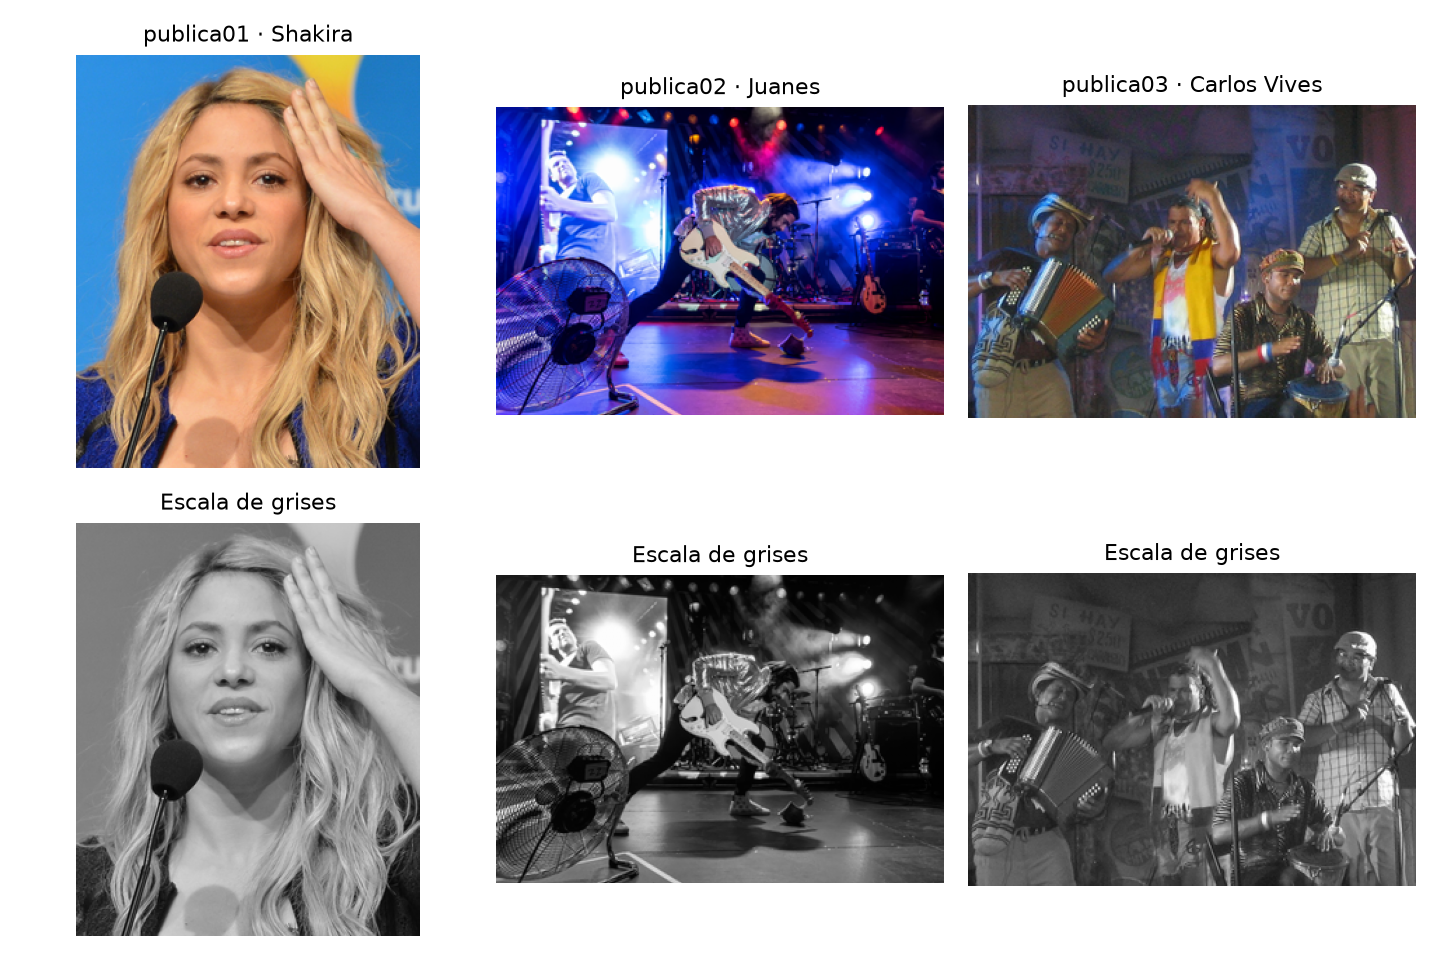

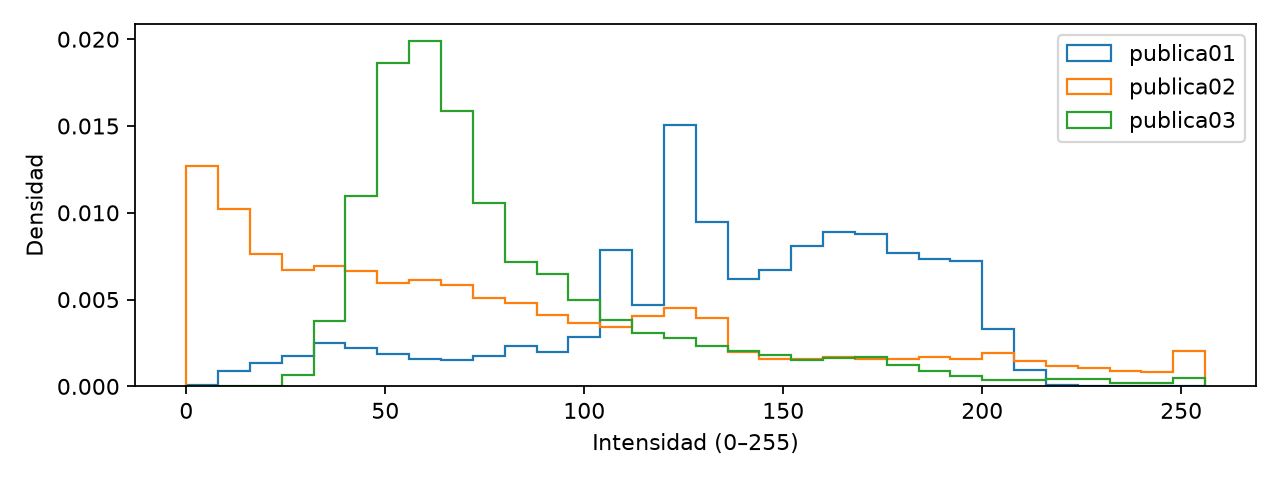

In [3]:
from IPython.display import Image as MostrarImagen, display
for nombre in ['publicas_panel.png','publicas_histogramas.png']:
    display(MostrarImagen(filename=str(OUT / nombre)))

## Lectura crítica
Las imágenes tienen encuadres, luces y tamaños distintos. Los indicadores describen la escena completa y requieren interpretar el histograma junto con la imagen. La varianza del Laplaciano responde a bordes, textura y ruido. Esta práctica corresponde al componente de calidad y preprocesamiento de la actividad 73148. Los fundamentos de redes siamesas se explican conceptualmente en el informe.